# SymPy Tutorial (2022): For Physicists, Engineers, and Mathematicians

https://www.youtube.com/watch?v=1yBPEPhq54M


<img src="../pics/cover.png" width=400> 



In [2]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

print("All imports succeeded!")

setuptools version: 69.5.1
All imports succeeded!


In [3]:
!python --version

Python 3.12.10


In [4]:
pwd


'c:\\Users\\crodr\\Tutoriales\\Physics\\Physics_Miscelanea\\SymPy Tutorial(2022)'

## Introduction

Symbols can be defined as follows:



In [ ]:
x = sp.symbols("x")

In [11]:
x

x

You can use various mathematical operators on the defined symbols

In [13]:
x**2

x**2

In [14]:
sp.cos(x)

cos(x)

In [15]:
y = sp.sin(x)
y

sin(x)

In [ ]:
z = y - x**2
z

-x**2 + sin(x)

There are many many functions built into sympy

In [ ]:
# sp.

Can save expressions in new variables


In [ ]:
y = x**2 + 4 * x + 3
y

x**2 + 4*x + 3

Do operations on the new variables:

In [19]:
z = y**2
z

(x**2 + 4*x + 3)**2

Note that it doesn't expand. There are different methods you need to call to do different things with the expression:

In [20]:
z.factor()

(x + 1)**2*(x + 3)**2

In [21]:
z.expand()

x**4 + 8*x**3 + 22*x**2 + 24*x + 9

In the notation sp.solve(f,x), sympy finds the value of x that makes f(x)=0

In [22]:
sp.solve(z, x)

[-3, -1]

In [23]:
sp.solve(sp.sin(x), x)

[0, pi]

**Good Practice**: If you know that your variable x is real (and in some cases non-negative) it's good to specify this when you define your variables to prevent complicated issues when solving complicated problems (specially with integrals).

In [ ]:
x = sp.symbols("x")
sp.solve(x**2 + 1, x)

[-I, I]

In [ ]:
x = sp.symbols("x", real=True, positive=True)
sp.solve(x + 4, x)

[]

In [ ]:
x = sp.symbols("x", real=True)
sp.solve(x + 4, x)

[-4]

Can define many variables at once

In [ ]:
x, y, z = sp.symbols("x, y, z")
F = x**2 + sp.sin(z) * y
F

x**2 + y*sin(z)

Can also solve multivariable expressions specifying which variable we want to solve for. In each case, F = 0 is being solved for

In [ ]:
x_sols = sp.solve(F, x)
x_sols

[-sqrt(-y*sin(z)), sqrt(-y*sin(z))]

In [ ]:
y_sols = sp.solve(F, y)
y_sols

[-x**2/sin(z)]

In [ ]:
z_sols = sp.solve(F, z)
z_sols

[asin(x**2/y) + pi, -asin(x**2/y)]

Finally, it may be the case that one has a sympy expression but wants to convert into a numerical function so they can plot on a computer

In [34]:
expr = z_sols[0]
expr

asin(x**2/y) + pi

In [ ]:
expr_f = sp.lambdify([x, y], expr)
expr_f(1, 2)

np.float64(3.6651914291880923)

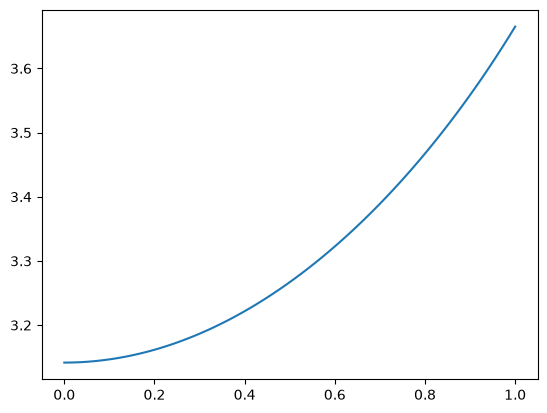

In [ ]:
x_num = np.linspace(0, 1, 100)
y_num = 2
plt.plot(x_num, expr_f(x_num, y_num))
plt.show()

For multivariable expressions, can also substitute values in

In [37]:
F

x**2 + y*sin(z)

In [ ]:
F.subs([(y, 3), (z, sp.pi / 2)])

x**2 + 3

## Examples

A falling object encounters a moving platform accelerating upwards:

1. Object $h_0(t) = h_0 - v_0 t - \frac{1}{2}g t^2$

2. Platform  $h_p(t) =  v_p t + \frac{1}{2}q t^2$

**Find the initial velocity $v_o$ such that when the object and platform collide, they are moving at the same speed.**

We need to solve for $v_o$ and t in the two equations

1. $h_0(t) = h_p(t)$

2. $\frac{dh_0}{dt}(t) = -\frac{dh_p}{dt}(t) $

In sympy, need to construct our system of equations as $EQ_1 = 0, EQ_2 = 0$, ... In our case, we rewrite then as

1. $h_0(t) - h_p(t) = 0$

2. $\frac{dh_0}{dt}(t) + \frac{dh_p}{dt}(t) = 0 $




In [44]:
t, h0, v0, g, vp, q = sp.symbols("t, h_0, v_0, g, v_p, q", real=True, positive=True)

Define expressions

In [ ]:
h0t = h0 - v0 * t - sp.Rational(1, 2) * g * t**2
dh0dt = g * t - v0
hpt = vp * t + sp.Rational(1, 2) * q * t**2
dhpdt = vp + q * t

Define equations

In [47]:
eq1 = h0t - hpt
eq2 = dh0dt + dhpdt

Solve the equations

In [50]:
t_collide, v_initfall = sp.solve([eq1, eq2], [t, v0])[0]

In [52]:
t_collide

(-2*v_p/3 + sqrt(2)*sqrt(3*g*h_0 + 3*h_0*q + 2*v_p**2)/3)/(g + q)

In [53]:
v_initfall

v_p/3 + sqrt(2)*sqrt(3*g*h_0 + 3*h_0*q + 2*v_p**2)/3

**What is the velocity when they collide**

In [ ]:
dh0dt.subs([(t, t_collide), (v0, v_initfall)]).simplify()

(-g*v_p - q*v_p/3 - q*sqrt(6*g*h_0 + 6*h_0*q + 4*v_p**2)/3)/(g + q)

In [ ]:
dhpdt.subs([(t, t_collide), (v0, v_initfall)]).simplify()

(g*v_p + q*v_p/3 + q*sqrt(6*g*h_0 + 6*h_0*q + 4*v_p**2)/3)/(g + q)

# Calculus (1st year)
Watch my video here for a more in depth discussion: https://www.youtube.com/watch?v=-SdIZHPuW9o

## Limits
$$\lim_{x \to \pi} \sin(x/2 + \sin(x))$$

In [ ]:
sp.limit(sp.sin(x / 2 + sp.sin(x)), x, sp.pi)

1

## Derivatives
$$\frac{d}{dx}\left( \frac{1 + \sin x}{1 - \cos x} \right)^2$$

In [ ]:
sp.diff(((1 + sp.sin(x)) / (1 - sp.cos(x))) ** 2, x)

2*(sin(x) + 1)*cos(x)/(1 - cos(x))**2 - 2*(sin(x) + 1)**2*sin(x)/(1 - cos(x))**3

$$\frac{d}{dx} f \left( x + g(x) \right)$$


In [ ]:
f, g = sp.symbols("f, g", cls=sp.Function)
g = g(x)
f = f(x + g)

In [8]:
f

f(x + g(x))

In [ ]:
dfdx = sp.diff(f, x)
dfdx

(Derivative(g(x), x) + 1)*Subs(Derivative(f(_xi_1), _xi_1), _xi_1, x + g(x))

In [ ]:
dfdx.subs([(g, sp.sin(x))]).doit()  # need to call doit

(cos(x) + 1)*Subs(Derivative(f(_xi_1), _xi_1), _xi_1, x + sin(x))

## Basic Antiderivatives

$$\int \csc(x) \cot(x) dx $$

In [13]:
sp.integrate(sp.csc(x) * sp.cot(x), x)

-1/sin(x)

## Definite Integrals


$$\int_{0}^{\ln(4)}\frac{e^x dt}{\sqrt{e^{2x}+9}} $$


In [ ]:
sp.integrate(sp.exp(x) / sp.sqrt(sp.exp(2 * x) + 9), (x, 0, sp.log(4)))

-asinh(1/3) + asinh(4/3)

$$\int_1^t x^{10} e^x dx$$

In [15]:
t = sp.symbols("t")

In [16]:
sp.integrate(x**10 * sp.exp(x), (x, 1, t))

(t**10 - 10*t**9 + 90*t**8 - 720*t**7 + 5040*t**6 - 30240*t**5 + 151200*t**4 - 604800*t**3 + 1814400*t**2 - 3628800*t + 3628800)*exp(t) - 1334961*E

# Examples

The hydrogen wave function is given by

$$\psi_{nlm} = R_{nl}(r)Y_l^m(\theta, \phi) $$

$$R_{nl}(r) =  \sqrt{\left(\frac{2}{na}\right)^3 \frac{(n-l-1)!}{2n[(n+1)!]}} e^{-r/na} \left(\frac{2r}{na}\right)^l \left[L_{n-l-1}^{2l+1}(2r/na)\right]$$

The mean distance from the nucleus of the electron:

$$\left<r\right> = \int R_{nl}^2 r^3 dr$$

The standard deviation in the distance from the nucleus of the electron:

$$\sigma = \sqrt{\left<r^2\right> - \left<r\right>^2} =  \sqrt{\left(\int_{0}^{\infty}R_{nl}^2 r^4 dr\right) - \left(\int_{0}^{\infty} R_{nl}^2 r^3 dr\right)^2}$$

In [17]:
from sympy import assoc_laguerre

In [28]:
assoc_laguerre?

Init signature: assoc_laguerre(n, alpha, x)
Docstring:     
Returns the $n$th generalized Laguerre polynomial in $x$, $L_n(x)$.

Examples

>>> from sympy import assoc_laguerre, diff
>>> from sympy.abc import x, n, a
>>> assoc_laguerre(0, a, x)
1
>>> assoc_laguerre(1, a, x)
a - x + 1
>>> assoc_laguerre(2, a, x)
a**2/2 + 3*a/2 + x**2/2 + x*(-a - 2) + 1
>>> assoc_laguerre(3, a, x)
a**3/6 + a**2 + 11*a/6 - x**3/6 + x**2*(a/2 + 3/2) +
    x*(-a**2/2 - 5*a/2 - 3) + 1

>>> assoc_laguerre(n, a, 0)
binomial(a + n, a)

>>> assoc_laguerre(n, a, x)
assoc_laguerre(n, a, x)

>>> assoc_laguerre(n, 0, x)
laguerre(n, x)

>>> diff(assoc_laguerre(n, a, x), x)
-assoc_laguerre(n - 1, a + 1, x)

>>> diff(assoc_laguerre(n, a, x), a)
Sum(assoc_laguerre(_k, a, x)/(-a + n), (_k, 0, n - 1))

Parameters

n : int
    Degree of Laguerre polynomial. Must be `n \ge 0`.

alpha : Expr
    Arbitrary expression. For ``alpha=0`` regular Laguerre
    polynomials will be generated.

See Also

jacobi, gegenbauer,
chebyshevt,

Define variables, be sure to specify their attributes

In [27]:
r, a = sp.symbols("r, a", real=True, positive=True)
n, l = sp.symbols("n, l", integer=True, positive=True)


Define $R_{nl}(r)$

In [ ]:
R = (
    sp.sqrt(
        (2 / (n * a)) ** 3 * sp.factorial(n - l - 1) / (2 * n * (sp.factorial(n + l)))
    )
    * sp.exp(-r / (n * a))
    * (2 * r / (n * a)) ** l
    * assoc_laguerre(n - l - 1, 2 * l + 1, (2 * r / (n * a)))
)
R

2*(2*r/(a*n))**l*exp(-r/(a*n))*assoc_laguerre(-l + n - 1, 2*l + 1, 2*r/(a*n))*sqrt(factorial(-l + n - 1))/(a**(3/2)*n**2*sqrt(factorial(l + n)))

We can check to make sure this corresponds to the radial wavefunctions we expect. Lets see $R_{10}(r)$

In [ ]:
R_10 = R.subs([(n, 1), (l, 0)])
R_10

2*exp(-r/a)/a**(3/2)

Function to compute $\int_0^\infty R_{nl}^2 r^k dr$ for particular values of n, l and k

In [ ]:
def compute_int(n_val, l_val, k):
    R_nl = R.subs([(n, n_val), (l, l_val)])
    return sp.integrate(R_nl**2 * r**k, (r, 0, sp.oo))

Compute the mean radial distance of an electron in the state $\psi_{100}$

In [34]:
compute_int(n_val=1, l_val=0, k=3)

3*a/2

Compute the spread $\sigma$ in distances of the electron in state $\psi_{100}$

In [ ]:
sp.sqrt(compute_int(n_val=1, l_val=0, k=4) - compute_int(n_val=1, l_val=0, k=3) ** 2)

sqrt(3)*a/2

Compute the mean radial distance of an electron in the state $\psi_{420}$

In [37]:
compute_int(n_val=4, l_val=2, k=3)

21*a

In [38]:
def compute_mean_distance(n_val, l_val=0):
    expr = compute_int(n_val, l_val, k=3)
    expr_f = sp.lambdify([a], expr)
    return expr_f(1)

In [ ]:
ns = np.arange(1, 10)
ds = [compute_mean_distance(ni) for ni in ns]

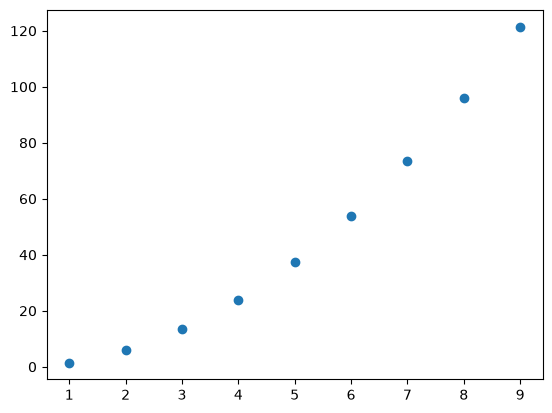

In [43]:
plt.scatter(ns, ds)

# Multivariable Calculus


In [ ]:
x, y, z, u1, u2, u3, v1, v2, v3, t = sp.symbols("x y z u_1 u_2 u_3 v_1 v_2 v_3 t")

## Vectors and Geometry

In [ ]:
u = sp.Matrix([u1, u2, u3])
v = sp.Matrix([v1, v2, v3])


In [7]:
u

Matrix([
[u_1],
[u_2],
[u_3]])

In [8]:
v

Matrix([
[v_1],
[v_2],
[v_3]])

### Addition and Multiplication

In [ ]:
2 * u + v

Matrix([
[2*u_1 + v_1],
[2*u_2 + v_2],
[2*u_3 + v_3]])

Dot product

In [10]:
u.dot(v)

u_1*v_1 + u_2*v_2 + u_3*v_3

Cross product

In [12]:
u.cross(v)

Matrix([
[ u_2*v_3 - u_3*v_2],
[-u_1*v_3 + u_3*v_1],
[ u_1*v_2 - u_2*v_1]])

Norm

In [13]:
u.norm()

sqrt(Abs(u_1)**2 + Abs(u_2)**2 + Abs(u_3)**2)

$\text{proj}_v(u) = \frac{u \cdot v}{|v|^2} v$

In [ ]:
proj_v_u = u.dot(v) / v.norm() ** 2 * v
proj_v_u

Matrix([
[v_1*(u_1*v_1 + u_2*v_2 + u_3*v_3)/(Abs(v_1)**2 + Abs(v_2)**2 + Abs(v_3)**2)],
[v_2*(u_1*v_1 + u_2*v_2 + u_3*v_3)/(Abs(v_1)**2 + Abs(v_2)**2 + Abs(v_3)**2)],
[v_3*(u_1*v_1 + u_2*v_2 + u_3*v_3)/(Abs(v_1)**2 + Abs(v_2)**2 + Abs(v_3)**2)]])

Lines: $\vec{r}(t) = \vec{r}_0 + t\vec{v}$

In [ ]:
r0 = sp.Matrix([1, 1, 1])
v = sp.Matrix([1, 3, -1])
r = r0 + t * v
r

Matrix([
[  t + 1],
[3*t + 1],
[  1 - t]])

Planes: $\vec{n} \cdot (P_0-\left<x,y,z\right>) = 0$

In [ ]:
P0 = sp.Matrix([4, 4, 8])
r = sp.Matrix([x, y, z])
n = sp.Matrix([1, 1, 1])
n.dot(P0 - r)


-x - y - z + 16

## Vector Calculus

### Vector Derivatives

In [ ]:
r = sp.Matrix([3 * t, sp.sin(t), t**2])
r

Matrix([
[   3*t],
[sin(t)],
[  t**2]])

In [19]:
sp.diff(r, t)

Matrix([
[     3],
[cos(t)],
[   2*t]])

**Example:** Find the angle between the velocity and acceleration as a function of time $\theta(t)$

In [ ]:
v = sp.diff(r, t)
a = sp.diff(v, t)
theta = sp.acos(v.dot(a) / (v.norm() * a.norm())).simplify()
theta


acos((4*t - sin(2*t)/2)/(sqrt(Abs(sin(t))**2 + 4)*sqrt(4*Abs(t)**2 + Abs(cos(t))**2 + 9)))

Find theta at t = 6

In [ ]:
theta.subs(t, 6).evalf()

0.251108015692338

### Vector Integrals

(Note: Will not add the +C)

In [ ]:
r = sp.Matrix([sp.exp(t) * sp.cos(t), t**4, 1 / (1 + t**2)])
r

Matrix([
[exp(t)*cos(t)],
[         t**4],
[ 1/(t**2 + 1)]])

In [ ]:
sp.Integral(r, t).doit()

Matrix([
[exp(t)*sin(t)/2 + exp(t)*cos(t)/2],
[                           t**5/5],
[                          atan(t)]])

Some cases integrals can't be solve analityically ==> see Second Year in Calculus Video

In [ ]:
from scipy.integrate import quad_vec

r = sp.Matrix([sp.exp(t**2) * sp.cos(t) ** 3, sp.exp(-(t**4)), 1 / (3 + t**2)])
r

Matrix([
[exp(t**2)*cos(t)**3],
[         exp(-t**4)],
[       1/(t**2 + 3)]])

In [ ]:
r_f = sp.lambdify([t], r)
quad_vec(r_f, 0, 1)[0]

array([[0.81549671],
       [0.84483859],
       [0.30229989]])

### Arclength

$$L = \int_a^b \sqrt{dx^2 + dy^2 + dz^2} = \int_a^b \sqrt{(dx/dt)^2 + (dy/dt)^2 +(dz/dt)^2} \; dt$$

Rare cases can be done symbolically. Find arclength of $\left<0,t,t^2\right>$ from t=0 to t=1

In [ ]:
r = sp.Matrix([0, t, t**2])
r

Matrix([
[   0],
[   t],
[t**2]])

In [ ]:
sp.diff(r, t).norm()

sqrt(4*Abs(t)**2 + 1)

In [ ]:
sp.integrate(sp.diff(r, t).norm(), (t, 0, 1))

asinh(2)/4 + sqrt(5)/2

# Examples

The magnetic field at a point $\vec{r}$ of a current configuration is 

$$\vec{B}(\vec{r}) = \frac{\mu_0}{4\pi}\int_t \frac{I \frac{d\vec{\ell}}{dt} \times (\vec{r}-\vec{\ell})}{|\vec{r}-\vec{\ell}|^3} dt $$

where $\vec{r} = (x,y,z)$ and $\vec{l} = (f(t), g(t), h(t))$ is a 1D curve in space that gives the location of the wire.

**Part 1: Use Sympy to find the integrand as a single 3-vector**

In [ ]:
x, y, z, t, I, mu0 = sp.symbols("x y z t I mu_0", real=True)
f, g, h = sp.symbols("f g h", cls=sp.Function)
f = f(t)
g = g(t)
h = h(t)

mu_0

Define: $\vec{r}, \vec{l}$ and $d\vec{l}/dt$

In [ ]:
r = sp.Matrix([x, y, z])
l = sp.Matrix([f, g, h])
dldt = sp.diff(l, t)

In [47]:
l

Matrix([
[f(t)],
[g(t)],
[h(t)]])

Define integrand

In [ ]:
dBdt = I * dldt.cross(r - l) / (r - l).norm() ** 3

In [51]:
dBdt

Matrix([
[I*(-(y - g(t))*Derivative(h(t), t) + (z - h(t))*Derivative(g(t), t))/(Abs(x - f(t))**2 + Abs(y - g(t))**2 + Abs(z - h(t))**2)**(3/2)],
[ I*((x - f(t))*Derivative(h(t), t) - (z - h(t))*Derivative(f(t), t))/(Abs(x - f(t))**2 + Abs(y - g(t))**2 + Abs(z - h(t))**2)**(3/2)],
[I*(-(x - f(t))*Derivative(g(t), t) + (y - g(t))*Derivative(f(t), t))/(Abs(x - f(t))**2 + Abs(y - g(t))**2 + Abs(z - h(t))**2)**(3/2)]])

**Part 2:** Find the magnetic field a distance H above a ring of radius R flowing clockwise


In [52]:
R, H = sp.symbols("R, H", real=True)

In [ ]:
dBdt = dBdt.subs(
    [(f, R * sp.cos(t)), (g, R * sp.sin(t)), (h, 0), (x, 0), (y, 0), (z, H)]
).doit()

dBdt.simplify()
dBdt

Matrix([
[H*I*R*cos(t)/(H**2 + R**2)**(3/2)],
[H*I*R*sin(t)/(H**2 + R**2)**(3/2)],
[      I*R**2/(H**2 + R**2)**(3/2)]])

Find the magnetic field

In [ ]:
mu0 / (4 * sp.pi) * sp.integrate(dBdt, [t, 0, 2 * sp.pi])

Matrix([
[                                   0],
[                                   0],
[I*R**2*mu_0/(2*(H**2 + R**2)**(3/2))]])

For more ccomplicated electrical wire configurations, see my video on solving for the magnetic field of an arbtriary wire (uses numerical integration)

## Partial/Directional Derivatives

In [ ]:
x, y, z = sp.symbols("x, y, z")

### Basics

partial Derivatives $\partial f/\partial x$ and $\partial f/\partial y$ of $f(x,y) = y^2 \sin(x+y)$

In [ ]:
f = y**2 * sp.sin(x + y)
sp.diff(f, x)

y**2*cos(x + y)

In [59]:
sp.diff(f, y)


y**2*cos(x + y) + 2*y*sin(x + y)

Or more complicated things like $\frac{\partial^3 f}{\partial x y^2}$

In [ ]:
sp.diff(f, y, y, x)

-y**2*cos(x + y) - 4*y*sin(x + y) + 2*cos(x + y)

### The Chain Rule

In [ ]:
t = sp.symbols("t")
x, y, z, w, v = sp.symbols("x, y, z, w, v", cls=sp.Function)

* Suppose $x$, $y$, and $z$ are functions of $t$ 
* $w$ is a function of $x$, $y$, and $z$. i.e $w=w(x,y,z)$

Find $dw/dt$

In [ ]:
x = x(t)
y = y(t)
z = z(t)
w = w(x, y, z)

In [66]:
w

w(x(t), y(t), z(t))

Can keep things in a more functional form:

In [ ]:
sp.diff(w, t)

Derivative(w(x(t), y(t), z(t)), x(t))*Derivative(x(t), t) + Derivative(w(x(t), y(t), z(t)), y(t))*Derivative(y(t), t) + Derivative(w(x(t), y(t), z(t)), z(t))*Derivative(z(t), t)

Or put in specific functions:

In [ ]:
w1 = x**2 * sp.exp(y) * sp.sin(z)
w1

x(t)**2*exp(y(t))*sin(z(t))

In [ ]:
w1 = x**2 + sp.exp(y) * sp.sin(z)
sp.diff(w1, t).subs([(x, sp.sin(t)), (y, sp.cos(t)), (z, t**2)]).doit()

2*t*exp(cos(t))*cos(t**2) - exp(cos(t))*sin(t)*sin(t**2) + 2*sin(t)*cos(t)

## Multiple Integrals

In rare cases these can be done symbolically:

$$\int_0^1 \int_0^{1-x^2} \int_3^{4-x^2-y^2} xdzdydx$$

In [ ]:
x, y, z = sp.symbols("x, y, z")
f = x
sp.integrate(f, (z, 3, 4 - x**2 - y**2), (y, 0, 1 - x**2), (x, 0, 1))

1/8

## Lagrangian Mechanics

The (simplified) idea of Lagrangian mechanics is the that kinetic energy and potential energy of a system can be expressed in terms of generalized coordinates and velocity

$$T = T(q,\dot{q}) \hspace{20mm} V=V(q,\dot{q})$$

where $q$ could be xyz of a point particle, or some angle $\theta$ (pendulum), or whatever makes the problem easiest to solve. The defining $L=T-V$, the following equation gives the equations of motion $q(t)$

$$\frac{dL}{dq} - \frac{d}{dt}\frac{dL}{d\dot{q}} = 0 $$

for all the different $q$'s of the system. The equation above gives a second order differential equation for all the different $q(t)$s.

**Example**: Find the equations of motion (in the form of differential equations)

<p align="center">
  <img src="../pics/symp_tut_p1.PNG" alt="drawing" width="300" align="center"/>
</p>

Let (x,y) be the pñosition of the pendulum bob

In [ ]:
t, R, g, m1, m2 = sp.symbols("t R g m_1 m_2")
z, theta = sp.symbols(r"z \theta", cls=sp.Function)
z = z(t)
theta = theta(t)

dzdt = sp.diff(z, t)
dthedt = sp.diff(theta, t)

Define locatain of pendulum

In [75]:
x = z + R * sp.sin(theta)
y = -R * sp.cos(theta)

In [76]:
y

-R*cos(\theta(t))

Kinetic and potential energies

In [ ]:
T1 = sp.Rational(1, 2) * m1 * sp.diff(z, t) ** 2
T2 = sp.Rational(1, 2) * m2 * sp.diff(x, t) ** 2 + sp.diff(y, t) ** 2
T = T1 + T2
V1 = 0
V2 = m2 * g * y
V = V1 + V2


Get Lagrangian

In [78]:
L = T - V
L

R**2*sin(\theta(t))**2*Derivative(\theta(t), t)**2 + R*g*m_2*cos(\theta(t)) + m_1*Derivative(z(t), t)**2/2 + m_2*(R*cos(\theta(t))*Derivative(\theta(t), t) + Derivative(z(t), t))**2/2

Get Lagranges equations of motion

In [ ]:
LE1 = sp.diff(L, z) - sp.diff(sp.diff(L, dzdt), t)
LE2 = sp.diff(L, theta) - sp.diff(sp.diff(L, dthedt), t)


In [80]:
LE1

-m_1*Derivative(z(t), (t, 2)) - m_2*(-2*R*sin(\theta(t))*Derivative(\theta(t), t)**2 + 2*R*cos(\theta(t))*Derivative(\theta(t), (t, 2)) + 2*Derivative(z(t), (t, 2)))/2

In [81]:
LE2

-2*R**2*sin(\theta(t))**2*Derivative(\theta(t), (t, 2)) - 2*R**2*sin(\theta(t))*cos(\theta(t))*Derivative(\theta(t), t)**2 - R*g*m_2*sin(\theta(t)) - R*m_2*(-R*sin(\theta(t))*Derivative(\theta(t), t)**2 + R*cos(\theta(t))*Derivative(\theta(t), (t, 2)) + Derivative(z(t), (t, 2)))*cos(\theta(t))

We want a system of two second order differential equations that we can solve

In [ ]:
sols = sp.solve([LE1, LE2], [sp.diff(z, t, t), sp.diff(theta, t, t)])

Find $d^2\theta / dt^2 = $

In [ ]:
sols[sp.diff(theta, t, t)]

R*m_1*m_2*sin(\theta(t))*cos(\theta(t))*Derivative(\theta(t), t)**2/(R*m_1*m_2*cos(\theta(t))**2 + 2*R*m_1*sin(\theta(t))**2 + 2*R*m_2*sin(\theta(t))**2) - 2*R*m_1*sin(\theta(t))*cos(\theta(t))*Derivative(\theta(t), t)**2/(R*m_1*m_2*cos(\theta(t))**2 + 2*R*m_1*sin(\theta(t))**2 + 2*R*m_2*sin(\theta(t))**2) - 2*R*m_2*sin(\theta(t))*cos(\theta(t))*Derivative(\theta(t), t)**2/(R*m_1*m_2*cos(\theta(t))**2 + 2*R*m_1*sin(\theta(t))**2 + 2*R*m_2*sin(\theta(t))**2) - g*m_1*m_2*sin(\theta(t))/(R*m_1*m_2*cos(\theta(t))**2 + 2*R*m_1*sin(\theta(t))**2 + 2*R*m_2*sin(\theta(t))**2) - g*m_2**2*sin(\theta(t))/(R*m_1*m_2*cos(\theta(t))**2 + 2*R*m_1*sin(\theta(t))**2 + 2*R*m_2*sin(\theta(t))**2)

Find $d^2 z / dt^2 = $

In [ ]:
sols[sp.diff(z, t, t)]

2*R*m_2*sin(\theta(t))**3*Derivative(\theta(t), t)**2/(m_1*m_2*cos(\theta(t))**2 + 2*m_1*sin(\theta(t))**2 + 2*m_2*sin(\theta(t))**2) + 2*R*m_2*sin(\theta(t))*cos(\theta(t))**2*Derivative(\theta(t), t)**2/(m_1*m_2*cos(\theta(t))**2 + 2*m_1*sin(\theta(t))**2 + 2*m_2*sin(\theta(t))**2) + g*m_2**2*sin(\theta(t))*cos(\theta(t))/(m_1*m_2*cos(\theta(t))**2 + 2*m_1*sin(\theta(t))**2 + 2*m_2*sin(\theta(t))**2)

With these two second order differential equations, the system can be numerically solved! (See any of my videos on Lagrangian mechanics)